In [90]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import PromptTemplate
from typing import TypedDict
from dotenv import load_dotenv

In [91]:
load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [92]:
class BlogState(TypedDict):
    topic: str
    outline: str
    content: str
    evaluation: str

In [93]:
def create_outline(state: BlogState) -> BlogState:
    title = state['topic']
    prompt = PromptTemplate(
        template = "Generate a detailed outline for a blog on the topic - {topic}",
        input_variables=["topic"]
    )
    outline = llm.invoke(prompt.invoke(title))

    return {"outline": outline.content}

In [94]:
def create_blog(state: BlogState) -> BlogState:
    topic = state['topic']
    outline = state['outline']
    prompt = PromptTemplate(
        template = 'Generate a blog on the title - {topic} using the following outline \n {outline}',
        input_variables=["topic", "outline"]
    )
    blog = llm.invoke(prompt.invoke({
    "topic": topic,
    "outline": outline
    }))

    return {"content": blog.content}

In [ ]:
def evaluate_blog(state: BlogState) -> BlogState:
    blog = state['content']
    outline = state['outline']
    prompt = PromptTemplate(
        template = "Evaluate the given blog for the outline - {outline} \n Blog - \n {blog}" ,
        input_variables=['outline', 'blog']
    )
    evaluation = llm.invoke(prompt.invoke({
        "outline": outline,
        "blog": blog
    }))
    return {"evaluation": evaluation}
    

In [96]:
graph = StateGraph(BlogState)

# add nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('evaluate_blog', evaluate_blog)

# add edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'evaluate_blog')
graph.add_edge('evaluate_blog', END)

# compile graph
workflow = graph.compile()


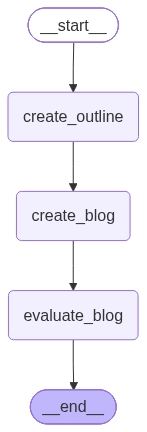

In [97]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [98]:
initial_state = {'topic': 'Artificial Intelligence'}
final_state = workflow.invoke(initial_state)
print(final_state)

{'topic': 'Artificial Intelligence', 'outline': [{'type': 'text', 'text': 'Here is a comprehensive and detailed outline for a pillar blog post about Artificial Intelligence. \n\n**Working Title Idea:** *Demystifying Artificial Intelligence: What It Is, How It Works, and What the Future Holds*\n**Target Audience:** Beginners to intermediate tech enthusiasts, business professionals, and curious minds looking for a clear, comprehensive overview of AI.\n**Estimated Word Count:** 2,000 – 2,500 words\n\n---\n\n# Blog Outline: Artificial Intelligence (AI) 101\n\n## I. Introduction\n*   **A. The Hook:** Start with a relatable scenario (e.g., Netflix recommending a show, asking Siri a question, or a self-driving car) to show how AI is already embedded in daily life.\n*   **B. The Buzz:** Acknowledge the current hype surrounding AI (ChatGPT, generative art, job market shifts).\n*   **C. Thesis Statement:** While AI often sounds like science fiction, it is a rapidly evolving tool rooted in mathem